<a href="https://colab.research.google.com/github/francescafarinaccio/Kepler_Classify_Exolpanets/blob/main/%5BIA_Ricerca_Scientifica%5D_Classify_Exoplanets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

FASE 0: CONFIGURAZIONE AMBIENTE

In [18]:
# 1. Installazione librerie esterne
!pip install shap -q

# 2. Import delle librerie standard e di Data Science
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 3. Import di Scikit-Learn
from sklearn.model_selection import (
    StratifiedShuffleSplit,
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)
from sklearn.utils import resample

# 4. Import dei Modelli Avanzati e Spiegabilità
from xgboost import XGBClassifier
import shap

# 5. Definizione delle Costanti Globali (UD1 L4)
SEED = 42
np.random.seed(SEED)

# 6. Montaggio Google Drive e Configurazione Percorsi
try:
    from google.colab import drive
    drive.mount('/content/drive')
    FILE_PATH = '/content/drive/MyDrive/Dataset/cumulative_2026.10.19_02.13.32.csv'
    print("Google Drive collegato con successo!")
except ImportError:
    FILE_PATH = 'cumulative_2026.10.19_02.13.32.csv'

# Fallback se il file si trova nel runtime locale di Colab
if not os.path.exists(FILE_PATH) and os.path.exists('cumulative_2026.10.19_02.13.32.csv'):
    FILE_PATH = 'cumulative_2026.10.19_02.13.32.csv'

print(f"Ambiente configurato con successo! Percorso dataset: {FILE_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive collegato con successo!
Ambiente configurato con successo! Percorso dataset: /content/drive/MyDrive/Dataset/cumulative_2026.10.19_02.13.32.csv


FASE 1: INGESTION DATASET

In [19]:
# 1. Lettura del file CSV NASA
df_raw = pd.read_csv(FILE_PATH, comment='#')

# 2. Selezione colonne e filtering binario (CONFIRMED vs FALSE POSITIVE)
columns_to_keep = [
    'koi_disposition', 'koi_period', 'koi_time0bk', 'koi_impact',
    'koi_duration', 'koi_depth', 'koi_prad', 'koi_teff',
    'koi_slogg', 'koi_srad', 'koi_smass', 'koi_steff',
    'koi_insol', 'koi_model_snr'
]

df_filtered = df_raw[[c for c in columns_to_keep if c in df_raw.columns]].copy()
df_binary = df_filtered[df_filtered['koi_disposition'].isin(['CONFIRMED', 'FALSE POSITIVE'])].copy()

# 3. Creazione target binario e drop della colonna stringa originale
df_binary['esopianeta_confermato'] = (df_binary['koi_disposition'] == 'CONFIRMED').astype(int)
df = df_binary.drop(columns=['koi_disposition']).reset_index(drop=True)

# 4. Rinomina delle colonne con nomi parlanti per rendere più chiare le variabili soprattutto se non è il proprio ambito di studi
nomi_parlanti = {
    'koi_period': 'periodo_orbitale_giorni',
    'koi_time0bk': 'tempo_primo_transito',
    'koi_impact': 'parametro_impatto',
    'koi_duration': 'durata_transito_ore',
    'koi_depth': 'profondita_transito_ppm',
    'koi_prad': 'raggio_pianeta_terrestre',
    'koi_teff': 'temp_equilibrio_pianeta_k',
    'koi_slogg': 'gravita_stella_logg',
    'koi_srad': 'raggio_stella_solare',
    'koi_smass': 'massa_stella_solare',
    'koi_steff': 'temp_stella_k',
    'koi_insol': 'flusso_insolazione',
    'koi_model_snr': 'snr_segnale_transito'
}

df = df.rename(columns=nomi_parlanti)

# 5. Output di verifica
print("--- SINTESI DATASET CARICATO ---")
print(f"Osservazioni: {df.shape[0]} | Variabili predittive: {df.shape[1] - 1}")
display(df.head(3))

--- SINTESI DATASET CARICATO ---
Osservazioni: 7587 | Variabili predittive: 12


,periodo_orbitale_giorni,tempo_primo_transito,parametro_impatto,durata_transito_ore,profondita_transito_ppm,raggio_pianeta_terrestre,gravita_stella_logg,raggio_stella_solare,massa_stella_solare,temp_stella_k,flusso_insolazione,snr_segnale_transito,esopianeta_confermato
0,9.488036,170.538750,0.146,2.95750,615.8,2.26,4.467,0.927,0.919,5455.0,93.59,35.8,1
1,54.418383,162.513840,0.586,4.50700,874.8,2.83,4.467,0.927,0.919,5455.0,9.11,25.8,1
2,1.736952,170.307565,1.276,2.40641,8079.2,33.46,4.564,0.791,0.836,5805.0,891.96,505.6,0


FASE 2: SPLIT ANTI LEAKAGE E PREPROCESSING

In [20]:
# 1. Separazione Feature e Target
X = df.drop(columns=['esopianeta_confermato'])
y = df['esopianeta_confermato']

# 2. Segregazione immediata del Test Set Hold-Out (20%)
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
for train_index, test_index in sss.split(X, y):
    X_train, X_test = X.iloc[train_index].copy(), X.iloc[test_index].copy()
    y_train, y_test = y.iloc[train_index].copy(), y.iloc[test_index].copy()

# 3. Definizione della Preprocessing Pipeline
preprocessing_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

print("--- FASE 2 COMPLETATA ---")
print(f"Training Set: {X_train.shape[0]} campioni | Test Set Isolato: {X_test.shape[0]} campioni")

--- FASE 2 COMPLETATA ---
Training Set: 6069 campioni | Test Set Isolato: 1518 campioni


FASE 3: TRAINING BASELINE vs XGBOOST + GRIDSEARCH VIEW

In [21]:
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring_metrics = ['roc_auc', 'f1', 'precision', 'recall']

# A. BASELINE: Regressione Logistica
baseline_pipeline = Pipeline([
    ('imputer', preprocessing_pipeline.named_steps['imputer']),
    ('scaler', preprocessing_pipeline.named_steps['scaler']),
    ('classifier', LogisticRegression(random_state=SEED, max_iter=1000))
])
cv_baseline = cross_validate(baseline_pipeline, X_train, y_train, cv=cv_stratified, scoring=scoring_metrics)

# B. MODELLO AVANZATO: XGBoost con GridSearch CV
xgb_pipeline = Pipeline([
    ('imputer', preprocessing_pipeline.named_steps['imputer']),
    ('scaler', preprocessing_pipeline.named_steps['scaler']),
    ('classifier', XGBClassifier(random_state=SEED, eval_metric='logloss', n_jobs=-1))
])

param_grid_xgb = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.03, 0.1],
    'classifier__subsample': [0.8, 1.0]
}

grid_search_xgb = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid_xgb,
    cv=cv_stratified,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)
grid_search_xgb.fit(X_train, y_train)
best_xgb_pipeline = grid_search_xgb.best_estimator_

cv_xgb_best = cross_validate(best_xgb_pipeline, X_train, y_train, cv=cv_stratified, scoring=scoring_metrics)

# C. TABELLA COMPARATIVA
risultati_cv = pd.DataFrame({
    'Metrica': ['ROC-AUC', 'F1-Score', 'Precision', 'Recall'],
    'Baseline (Logistic Reg)': [
        f"{cv_baseline['test_roc_auc'].mean():.4f} ± {cv_baseline['test_roc_auc'].std():.4f}",
        f"{cv_baseline['test_f1'].mean():.4f} ± {cv_baseline['test_f1'].std():.4f}",
        f"{cv_baseline['test_precision'].mean():.4f} ± {cv_baseline['test_precision'].std():.4f}",
        f"{cv_baseline['test_recall'].mean():.4f} ± {cv_baseline['test_recall'].std():.4f}"
    ],
    'XGBoost (Ottimizzato)': [
        f"{cv_xgb_best['test_roc_auc'].mean():.4f} ± {cv_xgb_best['test_roc_auc'].std():.4f}",
        f"{cv_xgb_best['test_f1'].mean():.4f} ± {cv_xgb_best['test_f1'].std():.4f}",
        f"{cv_xgb_best['test_precision'].mean():.4f} ± {cv_xgb_best['test_precision'].std():.4f}",
        f"{cv_xgb_best['test_recall'].mean():.4f} ± {cv_xgb_best['test_recall'].std():.4f}"
    ]
})

print("--- TABELLA COMPARATIVA IN CROSS-VALIDATION (5-FOLD) ---")
display(risultati_cv)

--- TABELLA COMPARATIVA IN CROSS-VALIDATION (5-FOLD) ---


,Metrica,Baseline (Logistic Reg),XGBoost (Ottimizzato)
0,ROC-AUC,0.8454 ± 0.0056,0.9770 ± 0.0032
1,F1-Score,0.6667 ± 0.0080,0.9030 ± 0.0076
2,Precision,0.6868 ± 0.0109,0.8959 ± 0.0143
3,Recall,0.6483 ± 0.0193,0.9104 ± 0.0047


FASE 4: VALUTAZIONE TEST-SET E CONFUSION MATRIX

--- VALUTAZIONE FINALE TEST SET ---
Accuracy Test: 0.9381  [IC 95%: 0.9256 - 0.9493]
F1-Score Test: 0.9147  [IC 95%: 0.8961 - 0.9304]
ROC-AUC Test:  0.9811  [IC 95%: 0.9746 - 0.9860]


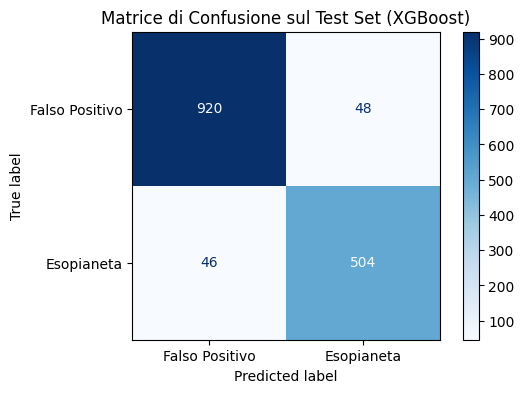

In [22]:
# 1. Predizione sul Test Set isolato
y_pred_test = best_xgb_pipeline.predict(X_test)
y_prob_test = best_xgb_pipeline.predict_proba(X_test)[:, 1]

# 2. Resampling Bootstrap per IC 95% (1.000 iterazioni)
n_bootstraps = 1000
boot_f1, boot_auc, boot_acc = [], [], []

for i in range(n_bootstraps):
    X_res, y_res = resample(X_test, y_test, random_state=SEED + i)
    y_pred_res = best_xgb_pipeline.predict(X_res)
    y_prob_res = best_xgb_pipeline.predict_proba(X_res)[:, 1]

    boot_f1.append(f1_score(y_res, y_pred_res))
    boot_auc.append(roc_auc_score(y_res, y_prob_res))
    boot_acc.append(accuracy_score(y_res, y_pred_res))

# Calcolo percentili per Intervallo di Confidenza al 95%
ic_f1_low, ic_f1_high = np.percentile(boot_f1, [2.5, 97.5])
ic_auc_low, ic_auc_high = np.percentile(boot_auc, [2.5, 97.5])
ic_acc_low, ic_acc_high = np.percentile(boot_acc, [2.5, 97.5])

test_acc = accuracy_score(y_test, y_pred_test)
test_f1 = f1_score(y_test, y_pred_test)
test_auc = roc_auc_score(y_test, y_prob_test)

print("--- VALUTAZIONE FINALE TEST SET ---")
print(f"Accuracy Test: {test_acc:.4f}  [IC 95%: {ic_acc_low:.4f} - {ic_acc_high:.4f}]")
print(f"F1-Score Test: {test_f1:.4f}  [IC 95%: {ic_f1_low:.4f} - {ic_f1_high:.4f}]")
print(f"ROC-AUC Test:  {test_auc:.4f}  [IC 95%: {ic_auc_low:.4f} - {ic_auc_high:.4f}]")

# 3. Matrice di Confusione
fig, ax = plt.subplots(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Falso Positivo", "Esopianeta"])
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Matrice di Confusione sul Test Set (XGBoost)")
plt.grid(False)
plt.show()

FASE 5: EXPLAINABILITY E SHAP VALUES

/tmp/ipykernel_3824/1215327393.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_df, show=False)


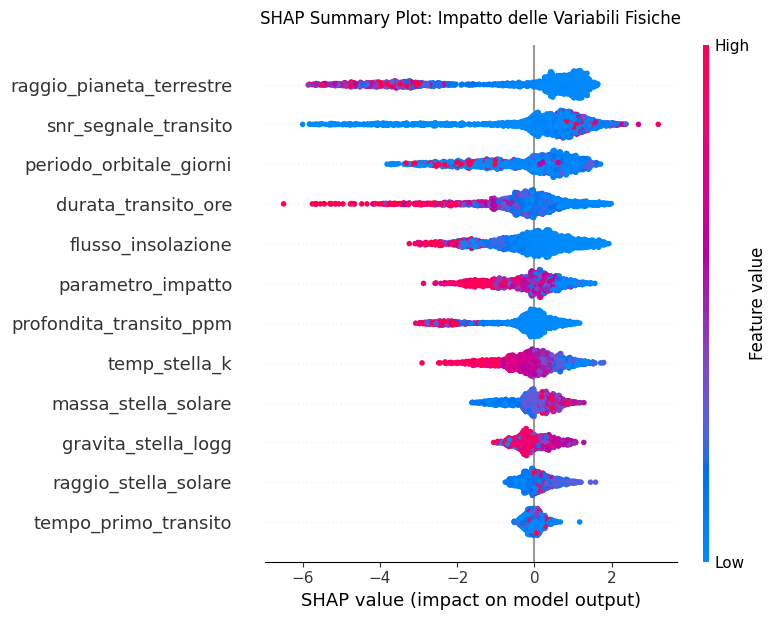

In [23]:
model_xgb = best_xgb_pipeline.named_steps['classifier']
preprocessor = Pipeline([
    ('imputer', best_xgb_pipeline.named_steps['imputer']),
    ('scaler', best_xgb_pipeline.named_steps['scaler'])
])

X_test_trans = preprocessor.transform(X_test)
X_test_df = pd.DataFrame(X_test_trans, columns=X_test.columns)

explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer(X_test_df)

# Grafico Summary Beeswarm
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_df, show=False)
plt.title('SHAP Summary Plot: Impatto delle Variabili Fisiche', fontsize=12, pad=15)
plt.tight_layout()
plt.show()